# CDS 303 – Final Project 2
## NYC Airbnb Listings: Data Integration and PCA

**Team Members:** Seohyun Hong, Sieun Woo, Seoyoung Yun

**Primary Dataset:** Inside Airbnb – New York City Listings (September 14, 2026)

**Source:** https://insideairbnb.com/get-the-data/

### Project Overview

Our project focuses on differences among Airbnb listings in New York City. In Project 1, we examined price, availability, and minimum-night requirements. For Project 2, we added ten supplementary datasets and applied PCA to find the main dimensions of variation. Every supplementary dataset contributes at least one PCA input variable. Our main audience is current and prospective Airbnb hosts in NYC.
We will perform clustering and classification in a later project stage.

### Input Files

Put the notebook, these eleven CSV files, and the `tl_2024_36_tract` shapefile folder in the same folder. The code uses relative paths, so no personal file paths are needed.

- `listings.csv`
- `calendar.csv`
- `CommonPlace_20261109.csv`
- `MTA_Subway_Stations_and_Complexes_20261117.csv`
- `nyc_airports.csv`
- `DOHMH_New_York_City_Restaurant_Inspection_Results_20261117.csv`
- `NYPD_Complaint_Data_Current_(Year_To_Date)_20261117.csv`
- `311_Service_Requests_from_2020_to_Present_20261117-2.csv`
- `BUS_Airbnb_Reduced.csv`
- `PLUTO_Airbnb_Reduced.csv`
- `ACSDT5Y2024.B25064-Data.csv`
- `tl_2024_36_tract/` (Census TIGER/Line 2024 tract shapefile: `.shp`, `.shx`, `.dbf`, `.prj`)

## Step 1. Import Libraries

We imported NumPy and Pandas to prepare the data, and Matplotlib and Seaborn to make graphs. We used Scikit-learn for location matching, standardization, and PCA. Our PCA code follows the professor's Demo 06.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings(action = 'ignore')

from pathlib import Path

Path('data').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

from sklearn.neighbors import BallTree

## Step 2. Load the Airbnb Dataset

We loaded the NYC Airbnb Listings dataset. It contains 29,918 listings and 90 variables. Each row represents one listing, and `id` identifies a listing. We only loaded one copy of the listings file.

In [2]:
df = pd.read_csv('listings.csv', low_memory = False)
print('Rows and columns:', df.shape)
print('Unique listing IDs:', df['id'].is_unique)
df.head()

Rows and columns: (29918, 90)
Unique listing IDs: True


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1352055619826961511,https://www.airbnb.com/rooms/1352055619826961511,20260914002229,2026-09-14,NaN,"New 3 bed, 1.5 bath",This stylish place to stay is perfect for grou...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,677651543,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,1215930899551057941,https://www.airbnb.com/rooms/1215930899551057941,20260914002229,2026-09-14,NaN,Queens apartament,Bring the whole family to this great place wit...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,392517036,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1203866180302079266,https://www.airbnb.com/rooms/1203866180302079266,20260914002229,2026-09-15,NaN,Luxury Meets Comfort Stay NYC,This stylish place is close to must-see destin...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,115082911,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,15310580,https://www.airbnb.com/rooms/15310580,20260914002229,2026-09-15,previous scrape,Nice apartment in Gramercy.,Nice apartment in one of the best neighbors of NY,NaN,https://a0.muscache.com/pictures/c2c78aad-78c9...,27336207,...,4.88,5.00,4.25,NaN,NaN,2,2,0,0,0.07
4,32842295,https://www.airbnb.com/rooms/32842295,20260914002229,2026-09-15,previous scrape,Beautiful bedroom and full bathroom,NaN,NaN,https://a0.muscache.com/pictures/b946d6e3-07d6...,233227636,...,4.89,4.78,4.75,NaN,NaN,1,0,1,0,0.40


## Step 3. Check the Project 1 Variables

We checked price, availability, and minimum-night requirements from Project 1. We also kept room type, borough, host listing count, and license information for later comparisons. Categorical variables are not used directly as PCA inputs.


In [3]:
clustering_vars = ['price', 'availability_30', 'availability_365', 'minimum_nights']
classification_vars = ['room_type', 'neighbourhood_group_cleansed',
                       'calculated_host_listings_count', 'license']
print(df[clustering_vars + classification_vars].dtypes)
df[clustering_vars + classification_vars].head()

price                                 str
availability_30                     int64
availability_365                    int64
minimum_nights                    float64
room_type                             str
neighbourhood_group_cleansed          str
calculated_host_listings_count      int64
license                               str
dtype: object


,price,availability_30,availability_365,minimum_nights,room_type,neighbourhood_group_cleansed,calculated_host_listings_count,license
0,NaN,30,365,30.0,Entire home/apt,Brooklyn,1,NaN
1,$164.55,29,364,31.0,Private room,Queens,1,NaN
2,NaN,30,269,30.0,Private room,Brooklyn,2,NaN
3,NaN,0,0,30.0,Entire home/apt,Manhattan,2,NaN
4,NaN,0,0,80.0,Private room,Brooklyn,1,NaN


## Step 4. Convert Price to a Number

The original price values contain dollar signs and commas. We converted price into a numerical variable called `price_num`. We did not replace missing prices with zero.


In [4]:
df['price_num'] = pd.to_numeric(
    df['price'].astype('string').str.replace(r'[\$,]', '', regex = True),
    errors = 'coerce'
)
df[['price', 'price_num']].head(10)

,price,price_num
0,NaN,<NA>
1,$164.55,164.55
2,NaN,<NA>
3,NaN,<NA>
4,NaN,<NA>
5,NaN,<NA>
6,NaN,<NA>
7,$236.00,236.0
8,$143.47,143.47
9,$102.97,102.97


## Step 5. Check Missing Values

We found 10,512 missing prices, or about 35.1% of the listings. We also compared availability for listings with and without reported prices. The missing-price group generally has lower availability. We use positive reported prices for our main PCA, but this sample may not represent all NYC listings.


In [5]:
basic_cols = ['price_num', 'availability_30', 'availability_365', 'minimum_nights']
missing = pd.DataFrame({
    'Missing Count': df[basic_cols].isna().sum(),
    'Missing %': (df[basic_cols].isna().mean() * 100).round(1)
})
print(missing)
print(pd.crosstab(df['availability_365'] == 0, df['price_num'].isna()))

df['has_price'] = df['price_num'].notna() & (df['price_num'] > 0)
price_comparison = df.groupby('has_price')[
    ['availability_30', 'availability_365', 'minimum_nights']
].median()
print('\nPrice availability comparison:')
print(price_comparison)

                  Missing Count  Missing %
price_num                 10512       35.1
availability_30               0        0.0
availability_365              0        0.0
minimum_nights                8        0.0
price_num         False  True 
availability_365              
False             19397   3503
True                  9   7009

Price availability comparison:
           availability_30  availability_365  minimum_nights
has_price                                                   
False                  0.0               0.0            30.0
True                  10.0             276.0            30.0


## Step 6. Summary Statistics and Graphs

We checked the distributions of price, availability, and minimum nights. We also used histograms to look for unusual values. Some listings had very high prices, so we reduced the effect of extreme values before PCA.


       price_num  availability_30  availability_365  minimum_nights
count    19406.0          29918.0           29918.0         29910.0
mean       310.2              9.4             188.8            26.8
std        574.1             11.7             140.5            28.5
min         17.7              0.0               0.0             1.0
25%        103.7              0.0              14.0            30.0
50%        182.4              2.0             227.0            30.0
75%        337.0             19.0             323.0            30.0
max      31537.8             30.0             365.0          1124.0
99th percentile price: 2000.0


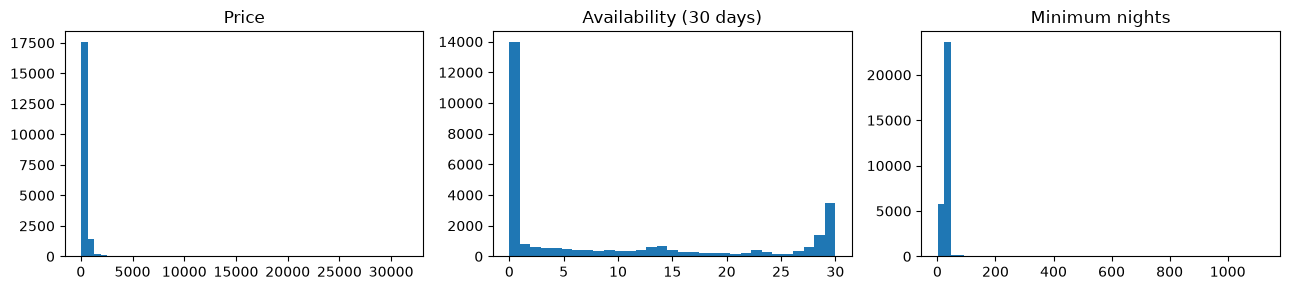

In [6]:
print(df[basic_cols].describe().round(1))
print('99th percentile price:', df['price_num'].quantile(.99))

fig, axes = plt.subplots(1, 3, figsize = (13, 3))
axes[0].hist(df['price_num'].dropna(), bins = 50)
axes[0].set_title('Price')
axes[1].hist(df['availability_30'], bins = 31)
axes[1].set_title('Availability (30 days)')
axes[2].hist(df['minimum_nights'].dropna(), bins = 50)
axes[2].set_title('Minimum nights')
plt.tight_layout()
plt.savefig('figures/airbnb_distributions.png', dpi = 150)
plt.show()

## Step 7. Prepare One Row per Listing

We kept the listing ID, coordinates, and useful listing variables. We removed invalid coordinates before matching outside datasets. Each row still represents one Airbnb listing.


In [7]:
cols = ['id', 'latitude', 'longitude', 'price_num', 'availability_30',
        'availability_365', 'minimum_nights', 'room_type',
        'neighbourhood_group_cleansed', 'calculated_host_listings_count', 'license',
        'number_of_reviews_ltm', 'estimated_occupancy_l365d', 'accommodates']
combined = df[cols].copy()
combined = combined.rename(columns={'latitude':'Latitude', 'longitude':'Longitude'})
combined = combined[
    combined['Latitude'].between(40.3, 41.1) &
    combined['Longitude'].between(-74.4, -73.4)
].copy()
print('Listings after coordinate check:', combined.shape)
print('Unique listing IDs:',combined['id'].is_unique)

Listings after coordinate check: (29918, 14)
Unique listing IDs: True


## Step 8. Summarize and Merge Calendar Data

The Calendar dataset has many dates for each listing. We summarized weekday and weekend availability by listing ID before merging. This prevents duplicate listing rows. An unavailable date may be booked or blocked, so it does not confirm occupancy.


In [8]:
calendar_parts = []
for chunk in pd.read_csv('calendar.csv',
                         usecols=['listing_id', 'date', 'available'],
                         chunksize=500000):
    chunk['weekend'] = pd.to_datetime(chunk['date']).dt.dayofweek >= 5
    chunk['open'] = (chunk['available'] == 't').astype(int)
    part = chunk.groupby(['listing_id', 'weekend'])['open'].agg(['sum', 'count'])
    calendar_parts.append(part)

calendar_sum = pd.concat(calendar_parts).groupby(level=[0,1]).sum().reset_index()
print('Number of listing/weekend groups:', len(calendar_sum))
calendar_sum.head()

Number of listing/weekend groups: 59836


,listing_id,weekend,sum,count
0,2539,False,226,261
1,2539,True,92,104
2,6848,False,202,261
3,6848,True,82,104
4,6872,False,247,261


In [9]:
calendar_wide = calendar_sum.pivot(index='listing_id', columns='weekend',
                                    values=['sum', 'count']).fillna(0)
calendar_wide.columns = ['_'.join([a, 'weekend' if b else 'weekday'])
                         for a, b in calendar_wide.columns]
calendar_wide = calendar_wide.reset_index()
calendar_wide['weekday_availability_rate'] = (
    calendar_wide['sum_weekday'] / calendar_wide['count_weekday'])
calendar_wide['weekend_availability_rate'] = (
    calendar_wide['sum_weekend'] / calendar_wide['count_weekend'])

calendar_summary = calendar_wide[['listing_id', 'weekday_availability_rate',
                                  'weekend_availability_rate']]
print('Unique calendar listing IDs:',calendar_summary['listing_id'].is_unique)
combined = combined.merge(calendar_summary, left_on='id', right_on='listing_id',
                          how='left', validate='one_to_one')
print('Rows after calendar merge:',len(combined))

Unique calendar listing IDs: True
Rows after calendar merge: 29918


## Step 9. Match Locations by Distance

Other NYC datasets do not have Airbnb listing IDs. We used latitude and longitude to find nearby locations. The distance calculations let us count nearby facilities and find the nearest subway station or airport.


In [10]:
listing_points = np.radians(combined[['Latitude','Longitude']].to_numpy())
earth_radius = 6371000

def clean_locations(data):
    data = data.copy()
    data['Latitude'] = pd.to_numeric(data['Latitude'], errors='coerce')
    data['Longitude'] = pd.to_numeric(data['Longitude'], errors='coerce')
    return data[data['Latitude'].between(40.3,41.1) &
                data['Longitude'].between(-74.4,-73.4)].copy()

def count_nearby(data, radius):
    tree = BallTree(np.radians(data[['Latitude','Longitude']]), metric='haversine')
    return tree.query_radius(listing_points, r=radius/earth_radius, count_only=True)

def nearest_km(data):
    tree = BallTree(np.radians(data[['Latitude','Longitude']]), metric='haversine')
    distance, index = tree.query(listing_points, k=1)
    return distance[:,0]*earth_radius/1000

## Step 10. Add Parks and Museums

We used NYC CommonPlace data to find parks and museums. We counted each type of facility within 1 kilometer of every Airbnb listing. These variables describe nearby recreational and cultural facilities.


In [11]:
common = pd.read_csv('CommonPlace_20261109.csv',
                     usecols=['PLACEID','the_geom','FACILITY TYPE','FACILITY DOMAINS'])
common = common.drop_duplicates('PLACEID')
points = common['the_geom'].str.extract(r'POINT\s*\(\s*([-\d.]+)\s+([-\d.]+)\s*\)')
common['Longitude'] = pd.to_numeric(points[0],errors='coerce')
common['Latitude'] = pd.to_numeric(points[1],errors='coerce')
common = clean_locations(common)

parks = common[(common['FACILITY TYPE']==4) & (common['FACILITY DOMAINS']==1)]
museums = common[(common['FACILITY TYPE']==3) & (common['FACILITY DOMAINS']==4)]
combined['parks_1km'] = count_nearby(parks, 1000)
combined['museums_1km'] = count_nearby(museums, 1000)
print('Parks:',len(parks),'Museums:',len(museums))

Parks: 1274 Museums: 95


## Step 11. Add Subway Access

We used the MTA dataset and kept one record per subway station complex. We calculated the distance in kilometers from each listing to the nearest station complex. This gives us a measure of subway access.


In [12]:
subway = pd.read_csv('MTA_Subway_Stations_and_Complexes_20261117.csv',
                     usecols=['Complex ID','Latitude','Longitude'])
subway = subway.drop_duplicates('Complex ID')
subway = clean_locations(subway)
combined['subway_distance_km'] = nearest_km(subway)
print('Subway complexes:',len(subway))

Subway complexes: 445


## Step 12. Add Airport Access

We used JFK, LGA, and EWR airports because they serve the NYC area. We calculated the distance from each listing to the nearest airport. This adds information about travel access.


In [13]:
airports = pd.read_csv('nyc_airports.csv')
airports = airports[airports['iata_code'].isin(['JFK','LGA','EWR'])]
airports = airports.rename(columns={'latitude_deg':'Latitude',
                                    'longitude_deg':'Longitude'})
airports = clean_locations(airports)
combined['airport_distance_km'] = nearest_km(airports)
print(airports[['iata_code','name']])

  iata_code                                   name
0       EWR   Newark Liberty International Airport
1       JFK  John F. Kennedy International Airport
2       LGA                      LaGuardia Airport


## Step 13. Add Restaurant Information

We used restaurant inspection records to count nearby restaurants. We kept one record per restaurant using `CAMIS`. To reduce the time difference with Airbnb data, we only used inspection dates on or before September 14, 2026. An earlier inspection does not prove that a restaurant was still open on that date.


In [14]:
rest = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20261117.csv',
                   usecols=['CAMIS','INSPECTION DATE','Latitude','Longitude'],
                   low_memory=False)
print('Original inspection rows:',len(rest))
rest['INSPECTION DATE'] = pd.to_datetime(rest['INSPECTION DATE'],errors='coerce')

rest = rest[rest['INSPECTION DATE'] <= '2026-09-14'].copy()
rest = rest.sort_values('INSPECTION DATE').drop_duplicates('CAMIS',keep='last')
rest = clean_locations(rest)
combined['restaurants_500m'] = count_nearby(rest, 500)
print('Restaurants with earlier inspection records:',len(rest))

Original inspection rows: 295040
Restaurants with earlier inspection records: 30161


## Step 14. Add NYPD Reported Incidents

We selected NYPD incidents from January through August 2026 and removed duplicate complaint IDs. We counted incidents within 1 kilometer of each listing. This is a count of reported incidents, not a direct measure of neighborhood safety.


In [15]:
crime = pd.read_csv('NYPD_Complaint_Data_Current_(Year_To_Date)_20261117.csv',
                    usecols=['CMPLNT_NUM','CMPLNT_FR_DT','Latitude','Longitude'],
                    low_memory=False)
crime = crime.drop_duplicates('CMPLNT_NUM')
crime['date'] = pd.to_datetime(crime['CMPLNT_FR_DT'],errors='coerce')
crime = crime[(crime['date'] >= '2026-01-01') &
              (crime['date'] < '2026-09-01')]
crime = clean_locations(crime)
combined['reported_incidents_1km'] = count_nearby(crime, 1000)
print('Jan–Aug 2026 reported incidents:',len(crime))

Jan–Aug 2026 reported incidents: 372940


## Step 15. Add NYC 311 Residential Noise Complaints

The 311 file was downloaded from NYC Open Data with two filters: Problem (formerly Complaint Type) = Noise - Residential and Created Date = September 14, 2025 – September 14, 2026. To keep the file small, we exported only five columns (`Unique Key`, `Created Date`, `Borough`, `Latitude`, `Longitude`). The complaint-type column is not in the file, but every row is a residential noise complaint.

We selected complaints from January through August 2026 to match the NYPD time window, removed duplicate keys, and counted complaints within 1 kilometer of each listing. In the code, this variable is named `service_requests_1km`, but it counts residential noise complaints. A complaint is a report, not a measured noise level.


In [16]:
requests = pd.read_csv('311_Service_Requests_from_2020_to_Present_20261117-2.csv',low_memory=False)
print('311 columns:',requests.columns.tolist())
requests = requests.drop_duplicates('Unique Key')
requests['date'] = pd.to_datetime(requests['Created Date'],
    format='%m/%d/%Y %I:%M:%S %p',errors='coerce')
requests = requests[(requests['date'] >= '2026-01-01') &
                    (requests['date'] < '2026-09-01')]
requests = clean_locations(requests)
combined['service_requests_1km'] = count_nearby(requests, 1000)
print('Jan–Aug 2026 requests in supplied extract:',len(requests))

311 columns: ['Unique Key', 'Created Date', 'Borough', 'Latitude', 'Longitude']
Jan–Aug 2026 requests in supplied extract: 249908


## Step 16. Count Nearby Airbnb Listings

We counted other Airbnb listings within 500 meters and excluded each listing itself. This measures nearby Airbnb supply, not actual bookings or demand.


In [17]:
airbnb_tree = BallTree(listing_points,metric='haversine')
combined['nearby_airbnb_listings_500m'] = (
    airbnb_tree.query_radius(listing_points,r=500/earth_radius,count_only=True)-1)
print(combined['nearby_airbnb_listings_500m'].describe().round(1))

count    29918.0
mean       209.8
std        184.2
min          0.0
25%         61.0
50%        172.0
75%        292.0
max        882.0
Name: nearby_airbnb_listings_500m, dtype: float64


## Step 16a. Add Bus Stops

The file `BUS_Airbnb_Reduced.csv` already contains, for each listing ID, the number of MTA bus stops within 500 meters (`bus_stops_500m`). We merged it by listing ID. Bus stops add transit access for areas that are far from the subway.

In [18]:
bus = pd.read_csv('BUS_Airbnb_Reduced.csv', encoding='utf-8-sig',
                  usecols=['id', 'bus_stops_500m'])
print('Bus file rows:', len(bus), '| Unique IDs:', bus['id'].is_unique)

combined = combined.merge(bus, on='id', how='left', validate='one_to_one')
print('Listings without a bus-stop count:', combined['bus_stops_500m'].isna().sum())
print(combined['bus_stops_500m'].describe().round(1))

Bus file rows: 29918 | Unique IDs: True
Listings without a bus-stop count: 0
count    29918.0
mean        28.6
std         13.0
min          0.0
25%         20.0
50%         28.0
75%         36.0
max         85.0
Name: bus_stops_500m, dtype: float64


## Step 16b. Add Building Characteristics (PLUTO)

PLUTO describes every tax lot in NYC. Airbnb coordinates are shifted by up to about 150 meters for privacy, so we did not match each listing to one building. Instead, we used all tax lots within 200 meters of each listing and calculated the median number of floors and the median year built. These variables describe the type of buildings around a listing (low-rise houses or high-rise apartments, older or newer buildings). Lots with 0 floors or a missing construction year were ignored.

In [19]:
pluto = pd.read_csv('PLUTO_Airbnb_Reduced.csv',
                    usecols=['bbl', 'numfloors', 'yearbuilt', 'latitude', 'longitude'],
                    low_memory=False)
pluto = pluto.drop_duplicates('bbl')
pluto = pluto.rename(columns={'latitude':'Latitude', 'longitude':'Longitude'})
pluto = clean_locations(pluto)
print('Tax lots:', len(pluto))

lot_tree = BallTree(np.radians(pluto[['Latitude','Longitude']]), metric='haversine')
lot_index = lot_tree.query_radius(listing_points, r=200/earth_radius)

def nearby_median(values, keep):
    result = []
    for index in lot_index:
        nearby = values[index]
        nearby = nearby[keep(nearby)]
        result.append(np.median(nearby) if len(nearby) > 0 else np.nan)
    return np.array(result)

combined['building_floors_200m'] = nearby_median(pluto['numfloors'].to_numpy(),
                                                 lambda v: v > 0)
combined['building_year_200m'] = nearby_median(pluto['yearbuilt'].to_numpy(),
                                               lambda v: v > 1800)
print(combined[['building_floors_200m', 'building_year_200m']].describe().round(1))

Tax lots: 857347
       building_floors_200m  building_year_200m
count               29901.0             29901.0
mean                    4.3              1920.2
std                     3.2                21.2
min                     1.0              1841.0
25%                     2.5              1910.0
50%                     3.0              1920.0
75%                     5.0              1930.0
max                    43.0              2020.0


## Step 16c. Add Median Rent by Census Tract (ACS)

We followed the professor's spatial-join example. We read the 2024 Census TIGER/Line tract polygons for New York State, converted them to EPSG:4326, turned each listing into a point, and used `gpd.sjoin(..., predicate='within')` to find the census tract of each listing. We then attached the tract's median gross rent (rent plus utilities) from the 2020–2024 ACS 5-year estimates (table B25064).

The ACS reports rents of $3,500 or more as "3,500+", so these tracts were set to $3,500. Some tracts have no estimate ("-"); these listings are filled with the median in Step 19. ACS values are five-year averages, not September 2026 rents.

In [20]:
import geopandas as gpd

tracts = gpd.read_file('tl_2024_36_tract/tl_2024_36_tract.shp')
tracts = tracts[['GEOID', 'geometry']].to_crs('EPSG:4326')

rent = pd.read_csv('ACSDT5Y2024/ACSDT5Y2024.B25064-Data.csv', skiprows=[1])
rent['GEOID'] = rent['GEO_ID'].str[-11:]
rent['median_rent'] = pd.to_numeric(
    rent['B25064_001E'].astype(str).str.replace(r'[+,]', '', regex=True),
    errors='coerce')
print('ACS tracts:', len(rent))
print('Tracts without an estimate:', rent['median_rent'].isna().sum())
print('Top-coded tracts ($3,500+):',
      rent['B25064_001E'].astype(str).str.contains(r'\+').sum())

listing_gdf = gpd.GeoDataFrame(
    combined[['id']],
    geometry=gpd.points_from_xy(combined['Longitude'], combined['Latitude']),
    crs='EPSG:4326')
joined = gpd.sjoin(listing_gdf, tracts, how='left', predicate='within')
joined = joined.drop_duplicates('id')
print('Listings without a tract:', joined['GEOID'].isna().sum())

combined = combined.merge(joined[['id', 'GEOID']], on='id', how='left',
                          validate='one_to_one')
combined = combined.merge(rent[['GEOID', 'median_rent']], on='GEOID', how='left',
                          validate='many_to_one')
print('Listings without a tract rent estimate:', combined['median_rent'].isna().sum())
print(combined['median_rent'].describe().round(0))

ACS tracts: 2327
Tracts without an estimate: 142
Top-coded tracts ($3,500+): 94
Listings without a tract: 0
Listings without a tract rent estimate: 266
count    29652.0
mean      2359.0
std        742.0
min        283.0
25%       1791.0
50%       2261.0
75%       2986.0
max       3500.0
Name: median_rent, dtype: float64


## Step 17. Check the Combined Data

We combined the primary Airbnb data with ten supplementary datasets. Calendar records were summarized by `listing_id` before merging with `id`, and the bus-stop file was merged by `id`. Most other datasets were connected by geographic distance, and the ACS rent data was connected through a census-tract spatial join. After merging, we still had 29,918 listings and no duplicate listing IDs. Each row represents one listing.

Some datasets (CommonPlace, MTA subway, bus stops, and PLUTO) were downloaded after the September Airbnb snapshot. Parks, museums, transit stops, and buildings change slowly, so we use them as PCA inputs, but we do not treat them as exact September conditions. ACS rents are 2020–2024 five-year averages.


In [21]:
print('Original Airbnb rows:',len(df))
print('Combined rows:',len(combined))
print('Duplicate listing IDs:',combined['id'].duplicated().sum())
print('Number of variables:',len(combined.columns))

assert combined['id'].is_unique
assert len(combined) == len(df)
combined.to_csv('data/airbnb_integrated_part1.csv',index=False)
print('Saved: data/airbnb_integrated_part1.csv')

summary = pd.DataFrame({'Variable':combined.columns,
                        'Missing Count':combined.isna().sum().values,
                        'Missing %':(combined.isna().mean().values*100).round(1)})
summary.to_csv('data/integrated_missing_summary.csv',index=False)
print(summary.to_string(index=False))

Original Airbnb rows: 29918
Combined rows: 29918
Duplicate listing IDs: 0
Number of variables: 30
Saved: data/airbnb_integrated_part1.csv
                      Variable  Missing Count  Missing %
                            id              0        0.0
                      Latitude              0        0.0
                     Longitude              0        0.0
                     price_num          10512       35.1
               availability_30              0        0.0
              availability_365              0        0.0
                minimum_nights              8        0.0
                     room_type              0        0.0
  neighbourhood_group_cleansed              0        0.0
calculated_host_listings_count              0        0.0
                       license          24791       82.9
         number_of_reviews_ltm              0        0.0
     estimated_occupancy_l365d              0        0.0
                  accommodates              0        0.0
       

## Step 18. Research Question and Audience

**Research Question:** How do NYC Airbnb listings differ in their surroundings (nearby restaurants, museums, parks, transit, airports, competing Airbnb listings, building type, local rent, NYPD reports, and 311 noise complaints), in the settings a host controls (nightly price, minimum stay, calendar availability, and guest capacity), and in their booking activity (reviews and estimated booked nights in the past year), and which of these characteristics vary together?

**Audience:** NYC hosts who manage one or a few listings and are setting or changing their nightly price, minimum-night rule, and calendar availability. Property managers who set these policies for several small listings could use the same comparison.

**Relevance:** A host cannot change the location of a listing, but can change its price, minimum stay, and open dates. In NYC this choice also has a legal side: stays shorter than 30 nights require registration under Local Law 18. Many hosts also compare Airbnb with renting the unit to a long-term tenant. Hosts need to know which settings usually go together with more bookings, and how their price compares with similar listings and with local rents.

**Potential Use:** The PCA separates location (PC1), booking activity (PC2), and budget versus premium listings (PC3). A host could place their own listing along these dimensions and compare its price, rules, and bookings with listings that have a similar location. In the next project stage, clustering can turn these dimensions into groups of comparable listings. These results describe patterns in listings. They do not predict bookings, revenue, or profitability.

## Step 19. Select Variables for PCA

We used listings with positive reported prices because price is one of our main variables. Every supplementary dataset contributes at least one PCA input, so the PCA uses **20 numerical variables**:

| Source | PCA input variables |
|---|---|
| Listings (host settings) | log price, availability over 30 days, availability over 365 days, log minimum nights, log guest capacity (`accommodates`) |
| Listings (booking activity) | log reviews in the last 12 months, estimated booked nights in the last 365 days |
| Listings (location) | log nearby Airbnb listings within 500 m |
| Calendar | weekend gap (weekday availability rate − weekend availability rate) |
| NYPD | log reported incidents within 1 km |
| DOHMH | log restaurants within 500 m |
| CommonPlace | log parks within 1 km, log museums within 1 km |
| 311 | log residential noise complaints within 1 km |
| MTA subway | log distance to the nearest subway complex |
| MTA bus | bus stops within 500 m |
| Airports | distance to the nearest airport (JFK, LGA, EWR) |
| PLUTO | log median number of floors within 200 m, median year built within 200 m |
| ACS (via census tract) | log median gross rent of the listing's census tract |

**Booking activity.** Reviews in the last 12 months and estimated booked nights show whether a listing is actually being booked, which open calendar days cannot show. Inside Airbnb estimates booked nights from reviews, so listings with monthly stays, which receive fewer reviews, may be underestimated. About 52% of priced listings have 0 estimated booked nights.

**Calendar variable.** The weekday and weekend availability rates are almost the same as `availability_365` (correlations 0.996–0.998). Adding them would repeat the same information three times. Instead we used their difference. A positive weekend gap means weekend dates are less open than weekdays, so weekends fill up first. Most values are close to zero.

**Building variables.** We used median floors and median year built. We did not add the share of one- and two-family lots because it is strongly related to the number of restaurants (−0.79) and to building height (−0.73).

**Not used in PCA.** IDs, coordinates, and tract IDs are not measurements. Room type, borough, host listing count, and license status are categorical or used later to explain the groups, so we compare them with the PCA scores after PCA (Step 25). We did not add reviews in the last 30 days (correlation 0.78 with 12-month reviews), bedrooms (0.49 with guest capacity), estimated revenue (price × booked nights), or review scores (26% missing).

**Outliers, transformations, and missing values.** Price and minimum nights were capped at their 99th percentiles before taking logs (the price cap is $2,000). We used log1p for price, minimum nights, guest capacity, count variables, subway distance, building floors, and median rent because their distributions are skewed. Missing values were filled with the median: 7 minimum-night values, 14 building values, and 189 rent values (tracts without an ACS estimate).

In [22]:
priced = combined[combined['price_num'].notna() &
                  (combined['price_num'] > 0)].copy()

print('All listings:',len(combined))
print('Listings with reported prices:',len(priced))
print('Excluded listings:',len(combined)-len(priced))

# Cap extreme values, then log-transform skewed variables
priced['log_price'] = np.log1p(
    priced['price_num'].clip(upper=priced['price_num'].quantile(.99)))
priced['log_minimum_nights'] = np.log1p(
    priced['minimum_nights'].clip(upper=priced['minimum_nights'].quantile(.99)))

count_cols = ['nearby_airbnb_listings_500m', 'reported_incidents_1km',
              'restaurants_500m', 'parks_1km', 'museums_1km',
              'service_requests_1km', 'subway_distance_km',
              'number_of_reviews_ltm', 'accommodates',
              'building_floors_200m', 'median_rent']
for col in count_cols:
    priced['log_' + col] = np.log1p(priced[col])

# Calendar: weekday and weekend rates repeat availability_365,
# so we use the difference between them (weekend demand signal)
print(priced[['weekday_availability_rate', 'weekend_availability_rate',
              'availability_365']].corr().round(3))
priced['weekend_gap'] = (priced['weekday_availability_rate'] -
                         priced['weekend_availability_rate'])
print(priced['weekend_gap'].describe().round(3))

All listings: 29918
Listings with reported prices: 19406
Excluded listings: 10512
                           weekday_availability_rate  \
weekday_availability_rate                      1.000   
weekend_availability_rate                      0.998   
availability_365                               0.997   

                           weekend_availability_rate  availability_365  
weekday_availability_rate                      0.998             0.997  
weekend_availability_rate                      1.000             0.996  
availability_365                               0.996             1.000  
count    19406.000
mean        -0.000
std          0.018
min         -0.368
25%         -0.008
50%         -0.000
75%          0.006
max          0.454
Name: weekend_gap, dtype: float64


In [23]:
pca_vars = ['log_price', 'availability_30', 'availability_365',
            'log_minimum_nights', 'weekend_gap',
            'log_nearby_airbnb_listings_500m', 'log_reported_incidents_1km',
            'log_restaurants_500m', 'log_parks_1km', 'log_museums_1km',
            'log_service_requests_1km', 'log_subway_distance_km',
            'airport_distance_km', 'log_number_of_reviews_ltm',
            'estimated_occupancy_l365d', 'log_accommodates',
            'bus_stops_500m', 'log_building_floors_200m',
            'building_year_200m', 'log_median_rent']

airbnb_pca = priced[pca_vars].copy()
print('Missing values before imputation:')
print(airbnb_pca.isna().sum())
airbnb_pca = airbnb_pca.fillna(airbnb_pca.median())
print('PCA table:', airbnb_pca.shape)
assert not airbnb_pca.isna().any().any()
airbnb_pca.to_csv('data/airbnb_pca_input.csv',index=False)

Missing values before imputation:
log_price                            0
availability_30                      0
availability_365                     0
log_minimum_nights                   7
weekend_gap                          0
log_nearby_airbnb_listings_500m      0
log_reported_incidents_1km           0
log_restaurants_500m                 0
log_parks_1km                        0
log_museums_1km                      0
log_service_requests_1km             0
log_subway_distance_km               0
airport_distance_km                  0
log_number_of_reviews_ltm            0
estimated_occupancy_l365d            0
log_accommodates                     0
bus_stops_500m                       0
log_building_floors_200m            14
building_year_200m                  14
log_median_rent                    189
dtype: int64
PCA table: (19406, 20)


## Step 20. Standardize Variables

The variables have different units, including days, dollars, counts, kilometers, floors, and years. We used `StandardScaler` to put the PCA variables on the same scale. This follows the professor's Demo 06.


In [24]:
from sklearn.preprocessing import StandardScaler

airbnb_st = StandardScaler().fit_transform(airbnb_pca)
airbnb_st = pd.DataFrame(airbnb_st, columns = airbnb_pca.columns)
airbnb_st.head(10)

,log_price,availability_30,availability_365,log_minimum_nights,weekend_gap,log_nearby_airbnb_listings_500m,log_reported_incidents_1km,log_restaurants_500m,log_parks_1km,log_museums_1km,log_service_requests_1km,log_subway_distance_km,airport_distance_km,log_number_of_reviews_ltm,estimated_occupancy_l365d,log_accommodates,bus_stops_500m,log_building_floors_200m,building_year_200m,log_median_rent
0,-0.199096,1.363303,1.079222,0.605684,-0.207461,-1.999291,-2.019203,-1.169287,-0.385303,-0.893636,-2.010687,1.996802,-0.956951,-0.721551,-0.762232,1.240136,-0.696060,-1.027072,0.203806,-0.535699
1,0.224853,1.447230,1.088989,0.578106,0.003777,-0.750886,-0.062666,-0.456369,1.892255,-0.893636,1.081471,-0.279830,0.160055,-0.721551,-0.762232,-1.370820,-0.989051,0.932609,0.444968,0.228267
2,-0.360034,1.447230,1.040151,0.578106,0.430316,-2.099820,-2.231521,-1.080546,-0.171908,-0.893636,-2.342410,2.151908,-1.133823,-0.721551,-0.762232,0.806832,-1.648283,-1.027072,0.444968,-0.506727
3,-0.748750,1.363303,-0.727790,0.578106,0.747173,-1.577981,-1.065133,-0.163152,-1.457760,-0.893636,0.126503,-0.594871,1.951024,-0.721551,-0.762232,-1.370820,-0.989051,-1.027072,0.348503,-0.745815
4,-0.408195,1.363303,-0.727790,0.578106,0.747173,-1.388778,-1.059416,-0.301626,-1.457760,-0.893636,0.061611,-0.297070,1.993849,-0.721551,-0.762232,-1.370820,-0.989051,-1.027072,0.348503,-0.745815
5,-0.290012,1.447230,0.161065,0.578106,0.694364,-1.431810,-1.060367,-0.301626,-1.457760,-0.893636,0.080608,-0.259071,1.999719,-0.721551,-0.762232,-1.370820,-1.062299,-1.027072,0.444968,-0.745815
6,-0.914401,1.447230,1.088989,0.578106,0.003777,-1.477452,0.798115,-0.529151,-0.385303,-0.893636,1.155517,-0.542640,-1.530149,-0.721551,-0.762232,-0.407194,-0.549564,-0.361704,3.724759,-1.910989
7,-0.429948,1.447230,1.088989,0.578106,0.003777,-1.272725,-2.259277,-3.089305,-0.983190,-0.893636,-2.242124,4.568218,-2.278809,-0.721551,-0.762232,-0.407194,-1.648283,-1.027072,1.891934,0.187260
8,-0.678272,1.363303,1.079222,0.578106,-0.207461,-1.388778,0.360313,-1.169287,1.294368,-0.893636,1.035816,0.590107,-0.204963,-0.721551,-0.762232,-0.407194,-0.842555,-0.589382,2.133096,-1.490973
9,-0.672718,1.363303,-0.864536,0.578106,0.013933,-0.410607,0.086410,-0.222767,2.261940,-0.045232,1.230492,-0.506508,0.112034,-0.176162,-0.143523,-0.407194,-0.183324,0.576080,0.300271,-0.633994


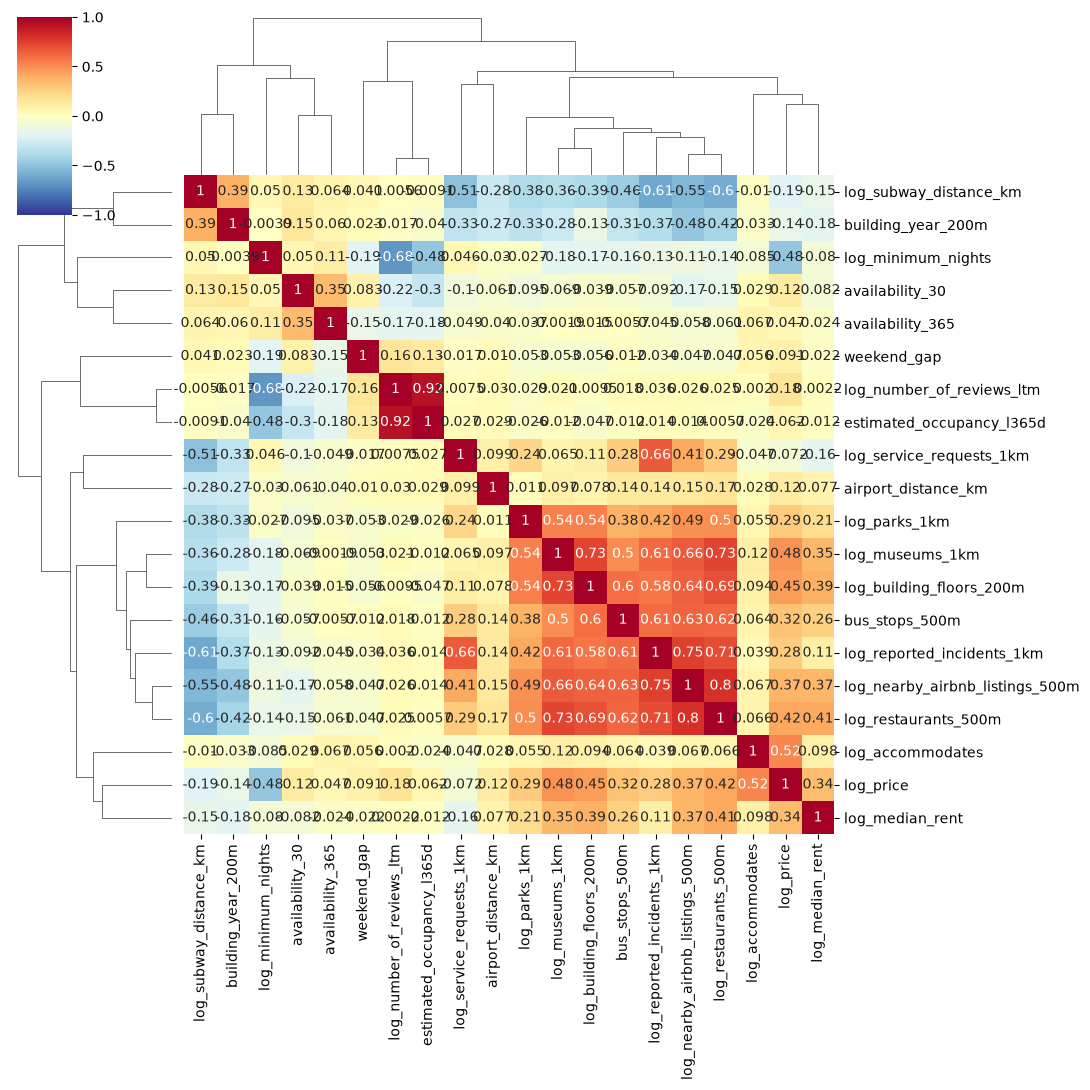

In [25]:
cor = airbnb_st.corr()
sns.clustermap(cor, annot = True, cmap = 'RdYlBu_r',
               vmin = -1, vmax = 1, figsize = (11,11))
plt.savefig('figures/correlation_clustermap.png',dpi=150,bbox_inches='tight')
plt.show()

## Step 21. Apply PCA

We applied PCA to the standardized data using the same method as Demo 06. We calculated all components first, then checked how much variance each component explained.


In [26]:
from sklearn.decomposition import PCA

pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(airbnb_st)

print('Eigenvalues:',pca.explained_variance_)
print('Explained variance ratio:',pca.explained_variance_ratio_)

Eigenvalues: [5.95894029 2.62986817 1.99600514 1.3111606  1.17237006 1.02683397
 0.96439599 0.78622485 0.69326778 0.60782938 0.54981249 0.47035501
 0.45634015 0.40232412 0.23211107 0.22101866 0.20381337 0.16439592
 0.11220826 0.04175538]
Explained variance ratio: [0.29793166 0.13148663 0.09979511 0.06555465 0.05861548 0.05133905
 0.04821731 0.03930922 0.0346616  0.0303899  0.02748921 0.02351654
 0.02281583 0.02011517 0.01160496 0.01105036 0.01019014 0.00821937
 0.00561012 0.00208766]


## Step 22. Explained Variance and Component Selection

We reported the explained variance ratio for every component. We also created a scree plot and a cumulative explained variance plot. We compared the eigenvalue-greater-than-one rule with the 80% cumulative variance rule.

The 80% rule selects **nine components**, which explain about 82.68% of the total variance. The eigenvalue rule keeps six components (70.46%). We use nine components so that the retained components keep at least 80% of the information while reducing 20 variables to nine. Only the first three components have a clear meaning; PC4–PC9 each explain less than 7% of the variance.

In [27]:
exp_variance_ratio = pca.explained_variance_ratio_
variance_table = pd.DataFrame({
    'PC':['PC'+str(i) for i in range(1,len(exp_variance_ratio)+1)],
    'Explained Variance Ratio':exp_variance_ratio,
    'Cumulative Variance':np.cumsum(exp_variance_ratio)
})
print(variance_table.round(4).to_string(index=False))
variance_table.to_csv('data/pca_explained_variance.csv',index=False)

  PC  Explained Variance Ratio  Cumulative Variance
 PC1                    0.2979               0.2979
 PC2                    0.1315               0.4294
 PC3                    0.0998               0.5292
 PC4                    0.0656               0.5948
 PC5                    0.0586               0.6534
 PC6                    0.0513               0.7047
 PC7                    0.0482               0.7529
 PC8                    0.0393               0.7922
 PC9                    0.0347               0.8269
PC10                    0.0304               0.8573
PC11                    0.0275               0.8848
PC12                    0.0235               0.9083
PC13                    0.0228               0.9311
PC14                    0.0201               0.9512
PC15                    0.0116               0.9628
PC16                    0.0111               0.9739
PC17                    0.0102               0.9841
PC18                    0.0082               0.9923
PC19        

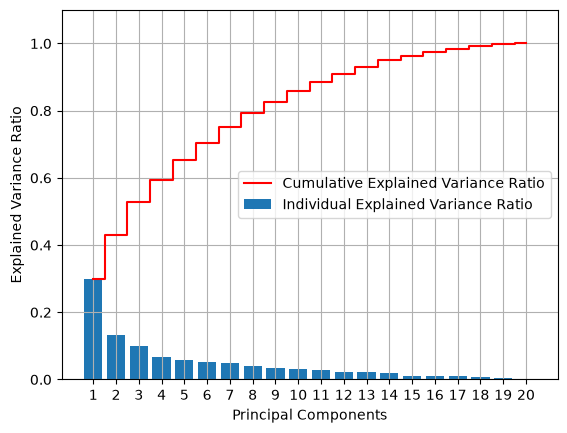

In [28]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1,len(exp_variance_ratio)+1)
    plt.bar(x_axis,exp_variance_ratio,align='center',
            label='Individual Explained Variance Ratio')
    plt.step(x_axis,np.cumsum(exp_variance_ratio),where='mid',
             color='red',label='Cumulative Explained Variance Ratio')
    plt.ylim(0,1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.legend()
    plt.grid()
    plt.savefig('figures/explained_variance_combined.png',dpi=150,bbox_inches='tight')
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

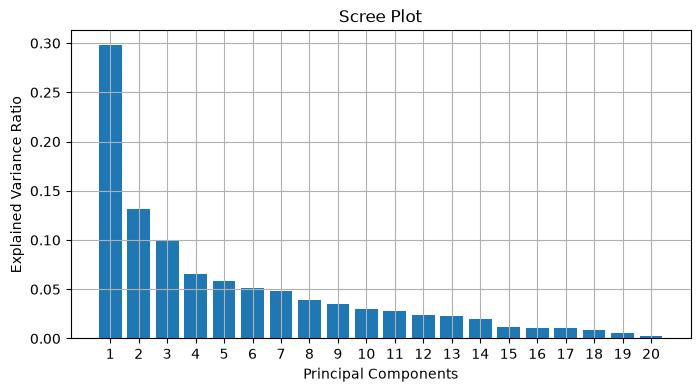

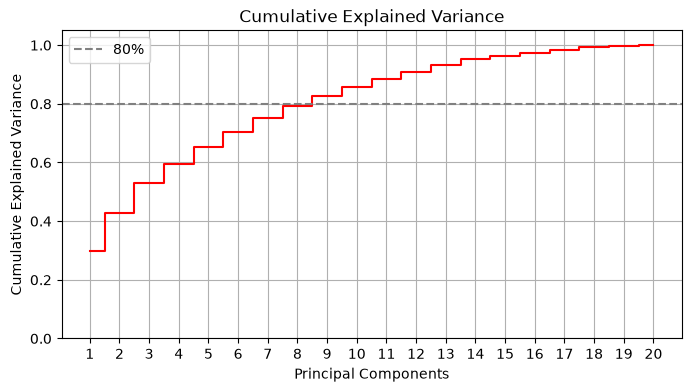

80% cumulative variance method: 9
Eigenvalue > 1 method: 6
Cumulative variance selected: 82.69 %


In [29]:
x_axis = range(1,len(exp_variance_ratio)+1)

# Scree plot
plt.figure(figsize=(8,4))
plt.bar(x_axis,exp_variance_ratio)
plt.xticks(x_axis)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid()
plt.savefig('figures/scree_plot.png',dpi=150,bbox_inches='tight')
plt.show()

# Cumulative explained variance plot
plt.figure(figsize=(8,4))
plt.step(x_axis,np.cumsum(exp_variance_ratio),where='mid',color='red')
plt.axhline(.80,color='gray',linestyle='--',label='80%')
plt.xticks(x_axis)
plt.ylim(0,1.05)
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid()
plt.savefig('figures/cumulative_explained_variance.png',dpi=150,bbox_inches='tight')
plt.show()

# Compare component selection rules
retained_80 = int(np.searchsorted(np.cumsum(exp_variance_ratio), .80) + 1)
retained_eigen = sum(pca.explained_variance_ > 1)
print('80% cumulative variance method:',retained_80)
print('Eigenvalue > 1 method:',retained_eigen)
print('Cumulative variance selected:',
      round(np.cumsum(exp_variance_ratio)[retained_80 - 1]*100,2),'%')
retained = retained_80

## Step 23. Interpret Component Loadings

We used the loading table to see which variables contributed most to each PC. We focused on the largest absolute loading values.

- **PC1 (29.78%) – Busy central location:** restaurants (0.37), nearby Airbnb listings (0.36), NYPD reports (0.34), museums (0.32), building floors (0.32), bus stops (0.30), and parks (0.26) are high; subway distance (−0.28) and building year (−0.21) are low. Central areas have taller and older buildings.
- **PC2 (13.15%) – Booking activity:** reviews in the last 12 months (0.58) and estimated booked nights (0.54) are high, and minimum nights is low (−0.47).
- **PC3 (9.98%) – Budget listings in noisy residential areas vs. premium listings:** noise complaints are high (0.45), while price (−0.43), guest capacity (−0.34), 30-day availability (−0.30), and local rent (−0.28) are low.
- **PC4 (6.56%) – Open dates in lower-rent areas:** 30-day availability (0.48), noise complaints (0.37), and 365-day availability (0.36) are high, and local rent is low (−0.38).
- **PC5–PC9 (23.21% together):** mixtures of airport distance, building year, weekend gap, guest capacity, parks, and local rent.

PC4–PC9 each explain less than 7% of the variance and mix several unrelated variables, so we interpret them with caution. The signs show directions, not better or worse outcomes.

In [30]:
loadings = pca.components_
num_pc = pca.components_.shape[1]
pc_list = ['PC'+str(i) for i in list(range(1,num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list,loadings)))
loadings_df['variable'] = airbnb_pca.columns.values
loadings_df = loadings_df.set_index('variable')

print(loadings_df.round(3).to_string())
loadings_df.to_csv('data/pca_loadings.csv')

                                   PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9   PC10   PC11   PC12   PC13   PC14   PC15   PC16   PC17   PC18   PC19   PC20
variable                                                                                                                                                                   
log_price                        0.215  0.164 -0.435  0.198  0.166  0.022  0.151  0.059  0.065 -0.203 -0.042 -0.065 -0.201  0.060  0.392 -0.109  0.618  0.010  0.011  0.026
availability_30                 -0.067 -0.179 -0.295  0.476 -0.198 -0.002 -0.355 -0.081  0.109 -0.416 -0.185  0.018  0.474 -0.122 -0.013 -0.011 -0.126 -0.010 -0.022 -0.032
availability_365                -0.030 -0.186 -0.222  0.364 -0.222 -0.539 -0.076 -0.295 -0.137  0.498  0.062 -0.042 -0.273  0.049  0.006  0.027 -0.004  0.014  0.014  0.001
log_minimum_nights              -0.096 -0.469  0.142 -0.164  0.123  0.035  0.093 -0.132 -0.036  0.330 -0.066 -0.040  0.516 -0.176  0.209 -0.

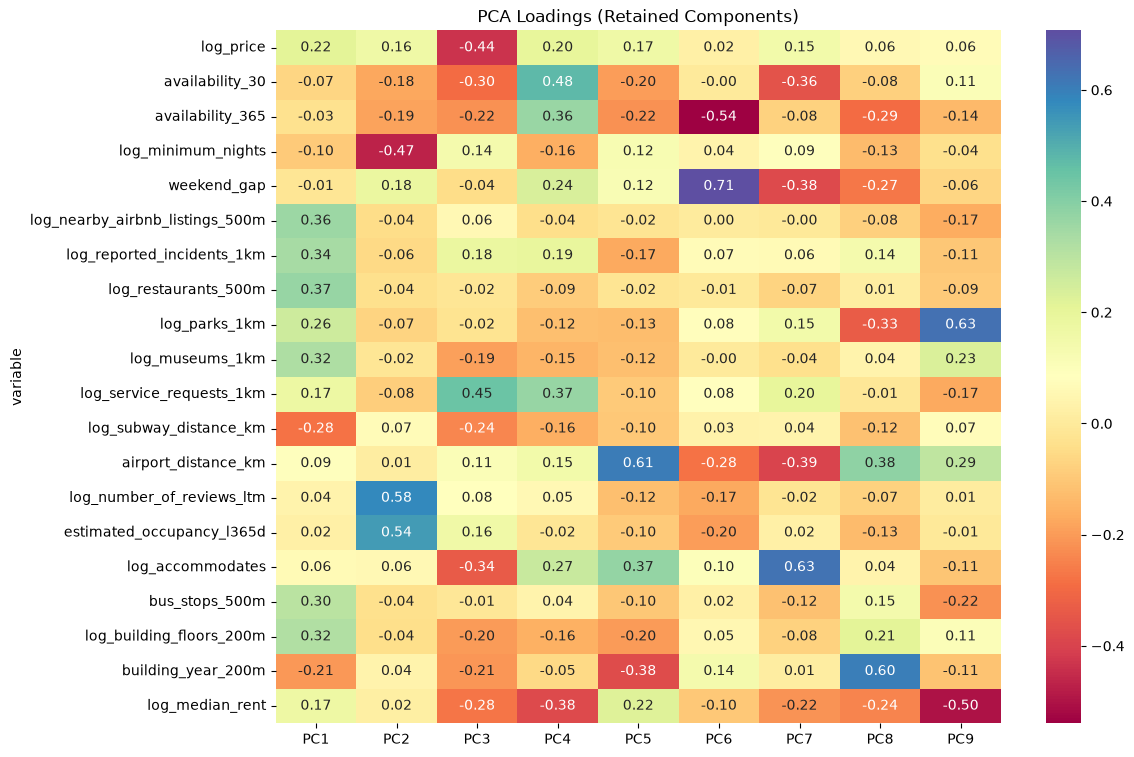

PC1 strongest loadings:
variable
log_restaurants_500m               0.366381
log_nearby_airbnb_listings_500m    0.361260
log_reported_incidents_1km         0.338935
log_museums_1km                    0.324117
Name: PC1, dtype: float64
PC2 strongest loadings:
variable
log_number_of_reviews_ltm    0.577861
estimated_occupancy_l365d    0.536892
log_minimum_nights           0.469018
availability_365             0.185671
Name: PC2, dtype: float64
PC3 strongest loadings:
variable
log_service_requests_1km    0.447194
log_price                   0.435161
log_accommodates            0.338076
availability_30             0.295390
Name: PC3, dtype: float64
PC4 strongest loadings:
variable
availability_30             0.476480
log_median_rent             0.379639
log_service_requests_1km    0.366508
availability_365            0.364286
Name: PC4, dtype: float64
PC5 strongest loadings:
variable
airport_distance_km    0.607936
building_year_200m     0.376070
log_accommodates       0.372830
availabilit

In [31]:
plt.figure(figsize=(max(7,retained*1.3),9))
ax = sns.heatmap(loadings_df.iloc[:,:retained],annot=True,
                 fmt='.2f',cmap='Spectral')
plt.title('PCA Loadings (Retained Components)')
plt.savefig('figures/pca_loadings_heatmap.png',dpi=150,bbox_inches='tight')
plt.show()

for pc in pc_list[:retained]:
    print(pc,'strongest loadings:')
    print(loadings_df[pc].abs().sort_values(ascending=False).head(4))

## Step 24. PCA Scores and Biplot

We calculated PCA scores for each listing. We created a biplot with PC1 and PC2, which together explain about 42.93% of the total variance. We plotted a random sample of 3,000 listings to make the graph easier to read.

The points represent listings and the arrows represent the input variables. The biplot does not confirm clusters.

In [32]:
scores = pca.transform(airbnb_st).transpose()
num_pc = pca.components_.shape[1]
pc_list = ['PC'+str(i) for i in list(range(1,num_pc+1))]
scores_df = pd.DataFrame.from_dict(dict(zip(pc_list,scores)))
scores_df.insert(0,'listing_id',priced['id'].to_numpy())
scores_df.to_csv('data/pca_scores.csv',index=False)
print(scores_df.head())

            listing_id       PC1       PC2       PC3       PC4       PC5  \
0  1215930899551057941 -4.079865 -0.915851 -2.514600  0.261712  0.197472   
1   791539646807027059 -0.297149 -1.750375 -0.089392  0.763581 -1.047278   
2   984905638210475309 -4.622577 -0.766826 -2.651547 -0.011394  0.006132   
3             42220146 -2.538761 -0.960751  1.105226  0.916484  1.335712   
4             42220001 -2.536001 -0.883240  0.874959  0.924502  1.392870   

        PC6       PC7       PC8       PC9  ...      PC11      PC12      PC13  \
0 -0.295721  0.588102 -0.950156  0.550849  ...  0.693758  0.740727  0.366803   
1 -0.178560 -0.888657 -0.666945  1.311755  ... -2.161212  0.143553 -0.327649   
2  0.168682  0.151346 -1.313572  0.912865  ...  0.334457  0.067570  0.159502   
3  0.363381 -2.273949  1.162759  0.494066  ... -0.639281 -0.405382  0.031565   
4  0.365363 -2.231771  1.148852  0.541783  ... -0.469147 -0.462038  0.065689   

       PC14      PC15      PC16      PC17      PC18      PC19 

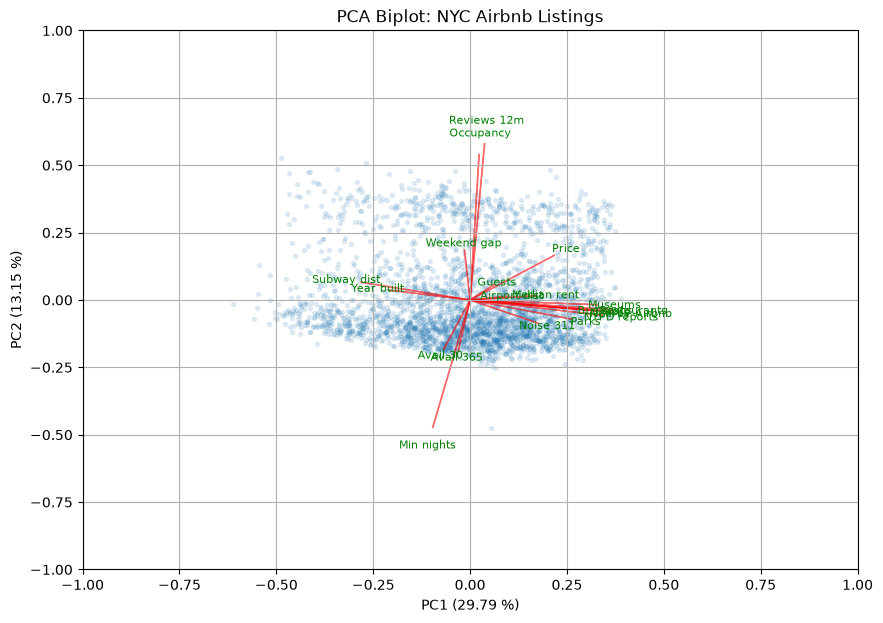

In [33]:
def biplot(score,coeff,pcax,pcay,labels=None):
    pca1 = pcax - 1
    pca2 = pcay - 1
    xs = score[:,pca1]
    ys = score[:,pca2]
    scalex = 1.0/(xs.max()-xs.min())
    scaley = 1.0/(ys.max()-ys.min())
    plt.figure(figsize=(10,7))
    plt.scatter(xs*scalex,ys*scaley,alpha=.12,s=8)
    n = coeff.shape[0]
    for i in range(n):
        plt.arrow(0,0,coeff[i,pca1],coeff[i,pca2],color='r',alpha=.5)
        label = 'Var'+str(i+1) if labels is None else labels[i]
        plt.text(coeff[i,pca1]*1.15,coeff[i,pca2]*1.15,
                 label,color='g',ha='center',va='center',fontsize=8)
    plt.xlim(-1,1)
    plt.ylim(-1,1)
    plt.xlabel(f'PC{pcax} ({pca.explained_variance_ratio_[pca1]*100:.2f} %)')
    plt.ylabel(f'PC{pcay} ({pca.explained_variance_ratio_[pca2]*100:.2f} %)')
    plt.title('PCA Biplot: NYC Airbnb Listings')
    plt.grid()
    plt.savefig('figures/pca_biplot.png',dpi=150,bbox_inches='tight')
    plt.show()

scores = pca.transform(airbnb_st)
np.random.seed(2000)
sample_ids = np.random.choice(len(scores),size=min(3000,len(scores)),replace=False)
short_names = ['Price','Avail 30','Avail 365','Min nights','Weekend gap',
               'Nearby Airbnb','NYPD reports','Restaurants','Parks','Museums',
               'Noise 311','Subway dist','Airport dist',
               'Reviews 12m','Occupancy','Guests',
               'Bus stops','Floors','Year built','Median rent']
biplot(scores[sample_ids],pca.components_.T,1,2,labels=short_names)

### What the Biplot Shows

- **One continuous cloud, no separate groups.** Most listings form one dense band near the center, with a thinner tail on the left. We do not see clearly separated groups, so we do not interpret this plot as showing clusters.
- **PC1 – location.** Restaurants, nearby Airbnb listings, NYPD reports, museums, building floors, bus stops, parks, local rent, and noise complaints point to the right; subway distance and building year point to the left.
- **PC2 – booking activity.** Reviews in the last 12 months and booked nights point up, while minimum nights points down. Listings that require shorter stays receive more reviews and more bookings.
- **Location and bookings are almost perpendicular.** The booking arrows are nearly at a right angle to the location arrows, so a central location alone does not mean more bookings.
- **Open dates point away from bookings.** The 30- and 365-day availability arrows point down, opposite to booked nights, so many open dates often mean fewer bookings.
- **Price lies between the two axes.** The price arrow points up and to the right, so price is related to both location and booking activity.
- **Limitation.** PC1 and PC2 together explain 42.93% of the variance, so this two-dimensional plot does not show the full structure.

## Step 25. What the Components Mean for Hosts

To make the components useful for hosts, we compared the average PC scores of listings with different host settings. Room type, borough, license status, and the 30-night rule were **not** PCA inputs, so this is an outside check of our interpretation. These are descriptive averages, not causal effects.

We also calculated a **price-to-rent ratio**: the nightly price × 30 divided by the median monthly rent of the listing's census tract. A ratio of 2 means that 30 nights on Airbnb are listed at twice the local median rent. This assumes every night is booked, and the ACS rent covers all rental units in the tract (including smaller and rent-regulated units), so the ratio is only a rough comparison.

In [34]:
# Compare average PC scores across host decisions (descriptive only)
lic = priced['license'].fillna('')
priced['license_status'] = np.where(lic.str.startswith('OSE'), 'registered',
                           np.where(lic.str.lower().str.contains('exempt'),
                                    'exempt', 'not reported'))
priced['stay_rule'] = np.where(priced['minimum_nights'] < 30,
                               'under 30 nights', '30+ nights')
priced['room_and_stay'] = priced['room_type'] + ' / ' + priced['stay_rule']

host_check = priced[['id','stay_rule','room_and_stay','license_status','room_type',
                     'neighbourhood_group_cleansed','price_num',
                     'estimated_occupancy_l365d', 'median_rent']].merge(
    scores_df[['listing_id'] + pc_list[:retained]],
    left_on='id', right_on='listing_id', how='inner', validate='one_to_one')

# Airbnb price for 30 nights compared with the tract's median monthly rent
host_check['price_to_rent'] = host_check['price_num'] * 30 / host_check['median_rent']

for group in ['stay_rule', 'room_and_stay', 'license_status', 'room_type',
              'neighbourhood_group_cleansed']:
    table = host_check.groupby(group)[pc_list[:retained]].mean().round(2)
    table['listings'] = host_check.groupby(group).size()
    table['median_price'] = host_check.groupby(group)['price_num'].median().round(0)
    table['mean_occupancy_days'] = host_check.groupby(group)['estimated_occupancy_l365d'].mean().round(0)
    table['median_price_to_rent'] = host_check.groupby(group)['price_to_rent'].median().round(2)
    print(table, '\n')

                  PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8   PC9  \
stay_rule                                                               
30+ nights      -0.33 -0.75  0.16 -0.13  0.09  0.02  0.05 -0.06 -0.02   
under 30 nights  0.92  2.07 -0.44  0.35 -0.24 -0.06 -0.15  0.17  0.06   

                 listings  median_price  mean_occupancy_days  \
stay_rule                                                      
30+ nights          14267         147.0                 45.0   
under 30 nights      5139         377.0                154.0   

                 median_price_to_rent  
stay_rule                              
30+ nights                        2.0  
under 30 nights                  4.66   

                                    PC1   PC2   PC3   PC4   PC5   PC6   PC7  \
room_and_stay                                                                 
Entire home/apt / 30+ nights       0.24 -0.62 -0.21 -0.18  0.35  0.01  0.35   
Entire home/apt / under 30 nights  1.48  2.60 -0.44

### Host Comparison Results

| Group | Listings | Median price | Mean booked nights | Price-to-rent | PC1 location | PC2 booking | PC3 budget |
|---|---|---|---|---|---|---|---|
| Minimum stay under 30 nights | 5,139 | $377 | 154 | 4.66 | 0.92 | **2.07** | −0.44 |
| Minimum stay 30+ nights | 14,267 | $147 | 45 | 2.00 | −0.33 | **−0.75** | 0.16 |
| Entire home, 30+ nights | 8,685 | $198 | 51 | 2.56 | 0.24 | −0.62 | −0.21 |
| Entire home, under 30 nights | 1,426 | $436 | 196 | 5.43 | 1.48 | 2.60 | −0.44 |
| Private room, 30+ nights | 5,446 | $77 | 36 | 1.22 | −1.24 | −0.94 | 0.73 |
| Private room, under 30 nights | 3,265 | $309 | 152 | 4.11 | 0.59 | 2.06 | −0.28 |
| Registered | 2,091 | $226 | 204 | 3.48 | −1.29 | **2.83** | 0.28 |
| License not reported | 14,839 | $153 | 48 | 2.07 | −0.21 | −0.66 | 0.10 |
| Manhattan | 8,757 | $265 | 71 | 3.20 | **2.07** | −0.17 | −0.26 |
| Brooklyn | 6,358 | $156 | 80 | 2.20 | −0.81 | 0.10 | 0.65 |
| Queens | 3,240 | $126 | 75 | 1.86 | **−3.03** | 0.30 | −0.59 |

- **PC1 is the market a host cannot change.** Manhattan scores highest and Queens lowest. A host should compare price with listings that have a similar PC1 score, not with the city average.
- **Location does not decide bookings.** Average booked nights are similar across boroughs (71 in Manhattan, 80 in Brooklyn, 75 in Queens), even though median prices differ a lot ($265 vs. $156 vs. $126).
- **The stay rule goes together with bookings.** Listings that accept stays under 30 nights have about 154 booked nights, compared with 45 for 30+ night listings. Registered listings, which may host stays under 30 nights under Local Law 18, have the highest PC2 average (2.83) and about 204 booked nights. Because booked nights are estimated from reviews, part of this gap may come from monthly guests leaving fewer reviews.
- **Comparison with long-term rent.** For entire homes with a 30-night minimum, 30 nights are listed at about 2.6 times the local median rent, but these listings average only about 51 estimated booked nights a year. For private rooms with a 30-night minimum, the ratio is about 1.2. A host can use this ratio to see how far their monthly Airbnb price is from the local rental market.
- **PC3 separates budget and premium listings.** Private and shared rooms and listings in Brooklyn and the Bronx score high on PC3 (lower price, noisier residential areas), while hotel rooms and Staten Island score low.

## Step 26. Discussion and Limitations

### Main Findings

Our combined dataset has 29,918 Airbnb listings with no duplicate listing IDs. We used 19,406 listings with a reported positive price and 20 numerical variables from the primary dataset and ten supplementary datasets. Nine principal components explain about 82.68% of the total variance:

- **PC1 (29.78%) – Busy central location:** many restaurants, competing Airbnb listings, NYPD reports, museums, bus stops, and taller, older buildings, close to the subway.
- **PC2 (13.15%) – Booking activity:** more reviews and booked nights with shorter minimum stays.
- **PC3 (9.98%) – Budget vs. premium listings:** lower price, fewer guests, and lower local rent in noisier residential areas.
- **PC4–PC9 (29.77% together):** open dates in lower-rent areas, airport distance, building year, weekend gap, and guest capacity; these are weaker and interpreted with caution.

The biplot shows one continuous cloud of listings, not separated groups.

### Intended Audience

For hosts who manage one or a few NYC listings, the main takeaway is that **location (PC1)**, **booking activity (PC2)**, and **budget versus premium positioning (PC3)** are separate dimensions. Location sets the price level and competition, but it does not decide how often a listing is booked. Booking activity goes together with the minimum-stay rule: listings that accept stays under 30 nights, which require registration, are booked far more often. The price-to-rent ratio lets a host compare a monthly Airbnb price with the local rental market. A host can first find listings with a similar location and size, and then compare their price, minimum stay, and bookings with those listings. The analysis does not predict bookings or profit.

### Limitations

About 35.1% of listings had missing prices and were excluded, so the results describe actively offered listings only. Booked nights are estimated by Inside Airbnb from reviews, so listings with monthly guests may be underestimated, and 52% of listings have 0 estimated booked nights. Unavailable calendar dates may be booked or blocked, and the weekend gap is close to zero for most listings. The 311 data include only residential noise complaints, and a complaint is a report rather than a measured noise level. NYPD counts are not direct safety scores.

The Airbnb data is from September 2026, but the CommonPlace, MTA subway, bus-stop, and PLUTO files were downloaded later, so they may not show exact September conditions. ACS rents are 2020–2024 averages, rents of $3,500 or more are top-coded at $3,500, and 142 tracts have no estimate. Restaurant records were limited to inspections on or before September 14, 2026, and NYPD and 311 records to January–August 2026. Airbnb coordinates are slightly shifted for privacy, so nearby counts, building medians, and tract assignments near tract borders are approximate.

PCA identifies directions of variation, not confirmed clusters. We will use the nine retained components in the next project stage.